# Demo — Orquestador multi-agente (Pre-entrega 6)

Muestra el **flujo de delegación**: el Supervisor decide quién interviene, el Investigador consulta las políticas, el Analista calcula, el Validador comprueba cada salida con código determinístico y la Síntesis cierra. Ejecutá las celdas en orden (requiere `.env` con la API key; ver README).

In [1]:
from IPython.display import Image, Markdown, display

from config import Settings
from escenarios import ESCENARIOS, ejecutar_escenario
from graph import compilar, construir_dependencias
from tracing import render_escenario

settings = Settings.from_env()
print(f"Proveedor: {settings.llm_provider} · modelo: {settings.modelo_activo}")
print(f"Retriever: {settings.retriever_backend}")
print(f"Topes: MAX_PASOS={settings.max_pasos} · MAX_REPARACIONES={settings.max_reparaciones}")
print(f"recursion_limit={settings.recursion_limit}")

Proveedor: openai · modelo: gpt-4o-mini
Retriever: local
Topes: MAX_PASOS=6 · MAX_REPARACIONES=2
recursion_limit=30


## 1. Topología del grafo

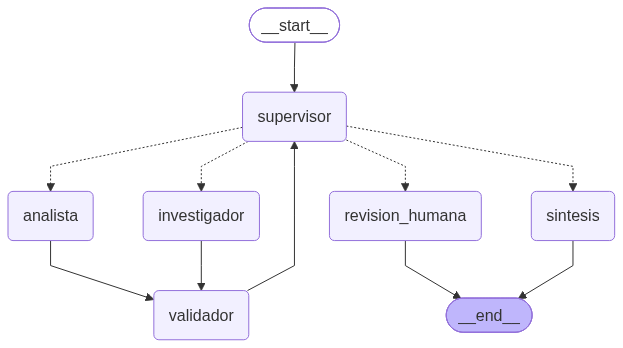

In [2]:
app = compilar(construir_dependencias(settings))
grafo = app.get_graph()
try:
    display(Image(grafo.draw_mermaid_png()))  # usa mermaid.ink (necesita red)
except Exception:
    display(Markdown("```mermaid\n" + grafo.draw_mermaid() + "\n```"))

## 2. Flujo completo (E1): Supervisor → Investigador → Analista → Síntesis

Cada línea `[n]` es un nodo del grafo; el supervisor explica *por qué* delega.

In [3]:
e1 = ESCENARIOS[0]
print(f"Usuario: {e1.pregunta}\n")
t1 = await ejecutar_escenario(e1, settings, on_evento=lambda e: print(f"[{e.orden}] {e.titulo}"))
print("\nRespuesta:", t1.respuesta)

Usuario: Un empleado lleva 12 años en TechCorp. Según la política de vacaciones, ¿cuántos días de vacaciones le corresponden por año y cuántos días suma en 3 años consecutivos manteniendo ese ritmo?



[1] supervisor decide → investigador (llm)


[2] investigador (intento 1): estado=completo, 3 hallazgo(s), confianza=1.00
[3] validador ✔ investigador aprobado


[4] supervisor decide → analista (llm)


[5] analista (intento 1): 28 * 3 = 84 (confianza=1.00)
[6] validador ✔ analista aprobado


[7] supervisor decide → FINISH (llm)


[8] sintesis: respuesta redactada

Respuesta: Un empleado con más de 10 años de antigüedad en TechCorp tiene derecho a 28 días corridos de vacaciones por año (fuente: política de vacaciones). 

En 3 años, el total de días de vacaciones que le corresponden es:  
28 días/año * 3 años = 84 días.

Advertencia: Este cálculo asume que el empleado mantiene el mismo ritmo de antigüedad y no hay cambios en la política de vacaciones.


In [4]:
print(render_escenario(t1))

=== E1 · Flujo completo: Investigador → Analista → Síntesis ===
Usuario: "Un empleado lleva 12 años en TechCorp. Según la política de vacaciones, ¿cuántos días de vacaciones le corresponden por año y cuántos días suma en 3 años consecutivos manteniendo ese ritmo?"
[1] supervisor decide → investigador (llm)
      razón: Falta el dato de cuántos días de vacaciones corresponden por año según la política de la empresa.
      instrucción: "Buscar la política de vacaciones de TechCorp para determinar cuántos días de vacaciones corresponden por año. Devolver el número de días de vacaciones por año y la fuente con cita textual."
      rúbrica: completitud ✘ · respaldo ✘ · consistencia ✘
[2] investigador (intento 1): estado=completo, 3 hallazgo(s), confianza=1.00
      herramienta: buscar_en_politicas_internas(pregunta="días de vacaciones por año") → [Fuente: politica_vacaciones.txt] Política de Vacaciones - TechCorp Los empleados con menos de 5 años de antigüedad acc…
[3] validador ✔ investiga

## 3. Estado compartido: quién aportó qué

Cada especialista escribe solo en su parcela (`research_output`, `analysis_output`); el validador marca `aprobaciones`; `decisiones` guarda el log del supervisor.

In [5]:
print("Investigador:", t1.research_output)
print("Analista:    ", t1.analysis_output)
print("Aprobaciones:", t1.aprobaciones, "· intentos:", t1.intentos)
for d in t1.decisiones:
    print(f"  decisión {d['paso']} [{d['origen']}] → {d['siguiente']}: {d['razon']}")

Investigador: {'consulta': 'días de vacaciones por año', 'estado': 'completo', 'hallazgos': [{'afirmacion': 'Los empleados con menos de 5 años de antigüedad acceden a 14 días corridos de vacaciones.', 'valor': 14.0, 'unidad': 'días corridos', 'fuente': 'politica_vacaciones.txt', 'cita': 'Los empleados con menos de 5 años de antigüedad acceden a 14 días corridos de vacaciones.'}, {'afirmacion': 'Los empleados con 5 a 10 años acceden a 21 días.', 'valor': 21.0, 'unidad': 'días corridos', 'fuente': 'politica_vacaciones.txt', 'cita': 'Los empleados con 5 a 10 años acceden a 21 días.'}, {'afirmacion': 'Los empleados con más de 10 años acceden a 28 días.', 'valor': 28.0, 'unidad': 'días corridos', 'fuente': 'politica_vacaciones.txt', 'cita': 'Los empleados con más de 10 años acceden a 28 días.'}], 'confidence_score': 1.0}
Analista:     {'expresion': '28 * 3', 'resultado': 84.0, 'explicacion': 'Se calculó el total de días de vacaciones para 3 años, multiplicando 28 días por año por 3 años.', 

## 4. Ruteo dinámico (E2 y E3)

No hay una ruta fija: si la pregunta ya trae los números va directo al analista (E2); si solo pide un dato, solo investiga (E3).

In [6]:
for esc in (ESCENARIOS[1], ESCENARIOS[2]):
    t = await ejecutar_escenario(esc, settings)
    print(f"{esc.id}: {' → '.join(t.orden_nodos)}\n   {t.respuesta[:200]}\n")

E2: supervisor → analista → validador → supervisor → sintesis
   El empleado acumuló un total de 231 días de vacaciones en 12 años en TechCorp. Este cálculo se realizó considerando 14 días por los primeros 5 años, 21 días por los siguientes 5 años y 28 días por los



E3: supervisor → investigador → validador → supervisor → sintesis
   El esquema estándar de teletrabajo consiste en 3 días de trabajo remoto y 2 días presenciales por semana. Esta información proviene de la fuente "politica_teletrabajo.txt". 

No hay advertencias o sup



## 5. Camino de fallo (E5, E7, E8)

E5: el validador rechaza un cálculo inconsistente y el supervisor reenvía el error específico. E7: un especialista lanza una excepción y se recupera. E8: la validación no se resuelve y se escala a revisión humana (sin bucle infinito).

In [7]:
for esc in (ESCENARIOS[4], ESCENARIOS[6], ESCENARIOS[7]):
    t = await ejecutar_escenario(esc, settings)
    print(render_escenario(t))
    print("-" * 80)

=== E5 · Reparación: el validador rechaza un cálculo inconsistente ===
Usuario: "Un empleado lleva 12 años en TechCorp. Según la política de vacaciones, ¿cuántos días de vacaciones le corresponden por año y cuántos días suma en 3 años consecutivos manteniendo ese ritmo?"
[1] supervisor decide → investigador (llm)
      razón: Falta el dato de cuántos días de vacaciones le corresponden por año según la política de la empresa.
      instrucción: "Buscar la política de vacaciones de TechCorp para determinar cuántos días de vacaciones le corresponden a un empleado por año. Devolver el número de días de vacaciones anuales y la fuente con cita textual."
      rúbrica: completitud ✘ · respaldo ✘ · consistencia ✘
[2] investigador (intento 1): estado=completo, 3 hallazgo(s), confianza=1.00
      herramienta: buscar_en_politicas_internas(pregunta="días de vacaciones anuales") → [Fuente: politica_vacaciones.txt] Política de Vacaciones - TechCorp Los empleados con menos de 5 años de antigüedad acc

investigador falló (intento 1): Falla simulada del especialista 'investigador'


=== E7 · Un especialista lanza una excepción y se recupera ===
Usuario: "Un empleado lleva 12 años en TechCorp. Según la política de vacaciones, ¿cuántos días de vacaciones le corresponden por año y cuántos días suma en 3 años consecutivos manteniendo ese ritmo?"
[1] supervisor decide → investigador (llm)
      razón: Falta el dato específico sobre los días de vacaciones que corresponden por año según la política de la empresa.
      instrucción: "Buscar la política de vacaciones de TechCorp para determinar cuántos días de vacaciones le corresponden a un empleado por año. Devolver el número de días de vacaciones anuales y la fuente con cita textual."
      rúbrica: completitud ✘ · respaldo ✘ · consistencia ✘
[2] investigador (intento 1): ErrorInyectado: Falla simulada del especialista 'investigador'
[3] validador ✘ investigador RECHAZADO: [ERROR_ESPECIALISTA] El investigador falló al ejecutarse: ErrorInyectado: Falla simulada del especialista 'investigador'
      error: [ERROR_ESPECIAL

=== E8 · Validación irresoluble → revisión humana ===
Usuario: "Un empleado lleva 12 años en TechCorp. Según la política de vacaciones, ¿cuántos días de vacaciones le corresponden por año y cuántos días suma en 3 años consecutivos manteniendo ese ritmo?"
[1] supervisor decide → investigador (llm)
      razón: Falta el dato específico sobre los días de vacaciones que corresponden por año según la política de la empresa.
      instrucción: "Buscar la política de vacaciones de TechCorp para determinar cuántos días de vacaciones le corresponden a un empleado por año. Devolver el número de días de vacaciones por año y la fuente con cita textual."
      rúbrica: completitud ✘ · respaldo ✘ · consistencia ✘
[2] investigador (intento 1): estado=completo, 3 hallazgo(s), confianza=1.00
      herramienta: buscar_en_politicas_internas(pregunta="días de vacaciones por año") → [Fuente: politica_vacaciones.txt] Política de Vacaciones - TechCorp Los empleados con menos de 5 años de antigüedad acc…
[3] 

## 6. Resumen

Las verificaciones automáticas de cada escenario están en `traces/traza_ejecucion.json` (generado con `python demo.py`).